# Caso 15 Densidad y probabilidad de variables aleatorias continuas

**Alumno:** Kevin Abraham Fernandez Sanchez  
**Matrícula:** 25041246  
**Materia:** Probabilidad y Estadística  
**Carrera:** Ingeniería Informática, Instituto Tecnológico de Durango (ITD)  
**Fecha:** 7 de octubre de 2026

## Introducción

Una variable aleatoria continua es la que puede tomar cualquier valor dentro de un rango de números reales, por ejemplo el tiempo que tarda en llegar una pizza o la calificación promedio de un alumno. Entre dos valores cualquiera siempre caben infinitos valores más, por eso no se puede hacer una tabla con la probabilidad de cada uno como en las variables discretas.

En lugar de eso se usa una **función de densidad de probabilidad (PDF)**, que se escribe $f(x)$. Una forma fácil de imaginarla: es como el polígono de frecuencias que saldría si tuviera una cantidad infinita de datos.

**Propiedades de una densidad:**

- Nunca es negativa: $f(x) \ge 0$
- El área total bajo la curva es 1 (el 100 %):

$$
\int_{-\infty}^{\infty} f(x)\,dx = 1
$$

**Otras cosas que vamos a calcular en este caso:**

- **Probabilidad de un intervalo** (es un área): $P(a \le X \le b) = \int_{a}^{b} f(x)\,dx$
- **Función de distribución acumulada (CDF):** $F(x) = P(X \le x) = \int_{-\infty}^{x} f(t)\,dt$
- **Valor esperado (media):** $\mu = \int_{-\infty}^{\infty} x \cdot f(x)\,dx$
- **Varianza:** $\sigma^2 = \int_{-\infty}^{\infty} (x-\mu)^2 \cdot f(x)\,dx$
- **Desviación estándar:** $\sigma = \sqrt{\sigma^2}$

## Objetivo

Calcular y visualizar densidades y probabilidades de funciones de variables aleatorias continuas.

## Descripción

Lo que se hace en este caso, en orden:

1. Cargar las librerías que se van a usar.
2. Cargar los datos (variables aleatorias continuas) desde 3 archivos CSV que subí a mi repositorio de GitHub y se leen con su enlace Raw.
3. Crear (definir) las funciones de densidad: dos funciones polinomiales, la uniforme, la normal, la chi cuadrada y una función inventada.
4. Visualizar cada densidad.
5. Comparar los datos de los CSV contra su densidad teórica.
6. Calcular probabilidades, la probabilidad acumulada, el valor esperado, la varianza y la desviación estándar.
7. Interpretar los resultados.

Los CSV están en mi repositorio: https://github.com/KevinFernandez07/Caso-15-Densidad-de-variables-aleatorias-continuas

## Cargar librerías

Para empezar cargo las librerías:

- `numpy` para los cálculos con arreglos.
- `pandas` para leer los archivos CSV con `pd.read_csv`.
- `matplotlib` para las gráficas.
- `math` para la función gamma que lleva la chi cuadrada.
- `scipy.stats` (`uniform`, `norm`, `chi2`) para comparar mis funciones contra las que ya trae la librería.
- `scipy.integrate.quad` para calcular integrales numéricas (áreas bajo la curva), que es como se sacan las probabilidades, la media y la varianza.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

from scipy.stats import uniform
from scipy.stats import norm
from scipy.stats import chi2
from scipy.integrate import quad

## Cargar datos

Los datos de las variables aleatorias continuas los guardé en 3 archivos CSV y los subí a mi repositorio de GitHub. Para leerlos uso el enlace **Raw** de cada archivo (es el enlace directo al contenido del CSV) con `pd.read_csv`. Así el notebook siempre carga los mismos datos, sin importar en qué computadora o en qué sesión de Colab lo corra.

Los 3 archivos tienen 1000 filas cada uno:

- `caso15_tiempos_pizza_uniforme.csv`: columnas `pedido` y `tiempo_minutos`. Tiempos de entrega de una pizza, repartidos de forma uniforme entre 20 y 40 minutos.
- `caso15_calificaciones_normal.csv`: columnas `alumno` y `calificacion`. Calificaciones de alumnos con una distribución normal de media 85 y desviación estándar 5.
- `caso15_chi_cuadrada_gl8.csv`: columnas `muestra` y `valor`. Valores de una chi cuadrada con 8 grados de libertad.

In [2]:
# Enlaces Raw de los CSV en mi repositorio de GitHub
url_pizza = "https://raw.githubusercontent.com/KevinFernandez07/Caso-15-Densidad-de-variables-aleatorias-continuas/refs/heads/main/caso15_tiempos_pizza_uniforme.csv"
url_calificaciones = "https://raw.githubusercontent.com/KevinFernandez07/Caso-15-Densidad-de-variables-aleatorias-continuas/refs/heads/main/caso15_calificaciones_normal.csv"
url_chi = "https://raw.githubusercontent.com/KevinFernandez07/Caso-15-Densidad-de-variables-aleatorias-continuas/refs/heads/main/caso15_chi_cuadrada_gl8.csv"

# Leer los CSV
df_pizza = pd.read_csv(url_pizza)
df_calificaciones = pd.read_csv(url_calificaciones)
df_chi = pd.read_csv(url_chi)

print("Pizza:          ", df_pizza.shape)
print("Calificaciones: ", df_calificaciones.shape)
print("Chi cuadrada:   ", df_chi.shape)

Pizza:           (1000, 2)
Calificaciones:  (1000, 2)
Chi cuadrada:    (1000, 2)


Reviso las primeras filas de cada tabla para confirmar que se cargaron bien y que las columnas son las que esperaba.

In [3]:
print("Tiempos de entrega de la pizza")
print(df_pizza.head())
print("\nCalificaciones de los alumnos")
print(df_calificaciones.head())
print("\nValores de la chi cuadrada")
print(df_chi.head())

Tiempos de entrega de la pizza
   pedido  tiempo_minutos
0       1           36.98
1       2           23.58
2       3           21.09
3       4           27.23
4       5           25.51

Calificaciones de los alumnos
   alumno  calificacion
0       1         81.99
1       2         85.61
2       3         88.28
3       4         82.71
4       5         89.11

Valores de la chi cuadrada
   muestra  valor
0        1   5.72
1        2  12.44
2        3  16.27
3        4   2.67
4        5   4.96


De cada tabla me quedo solo con la columna de datos (en un arreglo de numpy) para usarla más adelante en los histogramas y en los cálculos. También reviso que no falte ningún dato.

In [4]:
tiempos = df_pizza["tiempo_minutos"].to_numpy()
calificaciones = df_calificaciones["calificacion"].to_numpy()
datos_chi = df_chi["valor"].to_numpy()

print("Datos faltantes -> pizza:", df_pizza.isna().sum().sum(),
      "| calificaciones:", df_calificaciones.isna().sum().sum(),
      "| chi cuadrada:", df_chi.isna().sum().sum())
print("Cantidad de datos:", len(tiempos), len(calificaciones), len(datos_chi))

Datos faltantes -> pizza: 0 | calificaciones: 0 | chi cuadrada: 0
Cantidad de datos: 1000 1000 1000


## Crear funciones

### Funciones de densidad "de práctica"

Primero las tres funciones que no son distribuciones conocidas:

$$f(x) = x^{2} - 2 \qquad\qquad f(x) = x^{3} + 1 \qquad\qquad f(x)=(3x^6)^{\frac{1}{3}}$$

Más adelante voy a revisar si de verdad cumplen las propiedades de una densidad (spoiler: no todas).

In [5]:
# x al cuadrado menos 2
def f_x_cuad_menos_2(x):
    return x**2 - 2

# x al cubo mas 1
def f_x_cubo_mas_1(x):
    return x**3 + 1

# Función inventada: (3 * x^6) elevado a la 1/3
def f_x_inventada(x):
    return (3 * x**6) ** (1/3)

### Uniforme, normal y chi cuadrada

Ahora las densidades de las distribuciones conocidas. Las hice para que acepten un solo valor de `x` o un arreglo completo de valores, así las puedo usar directo para graficar.

**Uniforme.** Todos los valores entre $a$ y $b$ tienen la misma densidad, y fuera de ese intervalo es 0:

$$f(x) = \frac{1}{b-a} \quad \text{si } a \le x \le b$$

**Normal.** Tiene forma de campana, con media $\mu$ y desviación estándar $\sigma$:

$$f(x) =\frac{1}{\sigma \cdot \sqrt{2 \cdot \pi}}\cdot e^{\frac{-1}{2}\cdot \left( \frac {x - \mu}{\sigma}\right) ^2}$$

**Chi cuadrada.** Depende de los grados de libertad $k$ y solo existe para $x > 0$ ($\Gamma$ es la función gamma):

$$f(x) = \frac{x^{(k/2 - 1)} \cdot e^{(-x/2)}}{2^{(k/2)} \cdot \Gamma(k/2)}$$

In [6]:
# Densidad uniforme: 1/(b-a) dentro de [a, b] y 0 fuera
def f_x_uniforme(x, a, b):
    x = np.asarray(x, dtype=float)
    return np.where((x >= a) & (x <= b), 1 / (b - a), 0.0)

# Densidad normal con media y desviación estándar
def f_x_normal(x, media, desviacion_estandar):
    x = np.asarray(x, dtype=float)
    return (1 / (desviacion_estandar * np.sqrt(2 * np.pi))
            * np.exp(-0.5 * ((x - media) / desviacion_estandar) ** 2))

# Densidad chi cuadrada con k grados de libertad (solo para x > 0)
def f_x_chi_cuadrada(x, k):
    x = np.asarray(x, dtype=float)
    with np.errstate(divide='ignore', invalid='ignore'):
        fx = x ** (k / 2 - 1) * np.exp(-x / 2) / (2 ** (k / 2) * math.gamma(k / 2))
    return np.where(x > 0, fx, 0.0)

### Funciones auxiliares

Para no repetir código dejo listas unas funciones que voy a usar varias veces:

- `graficar_funcion`: dibuja una función sobre un rango de `x`.
- `graficar_datos_y_densidad`: dibuja el histograma de los datos del CSV y encima la curva de la densidad teórica.
- `graficar_area`: dibuja la densidad y sombrea el área entre dos valores (esa área es la probabilidad).
- `revisar_densidad`: comprueba las dos propiedades de una densidad (que no sea negativa y que el área total sea 1).
- `calcular_probabilidad`: integra la densidad entre dos valores.
- `calcular_media_varianza`: calcula valor esperado, varianza y desviación estándar con las integrales de la teoría.

In [7]:
def graficar_funcion(f, x, titulo, etiqueta):
    # Dibuja la función f evaluada en los valores x
    plt.figure(figsize=(8, 4.5))
    plt.plot(x, f(x), label=etiqueta)
    plt.title(titulo)
    plt.xlabel('Valor de x')
    plt.ylabel('f(x)')
    plt.axhline(0, color='gray', linewidth=0.8)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()


def graficar_datos_y_densidad(datos, f, x, titulo, etiqueta):
    # Histograma de los datos (normalizado) y la densidad teórica encima
    plt.figure(figsize=(8, 4.5))
    plt.hist(datos, bins=30, density=True, alpha=0.5, label='Datos del CSV')
    plt.plot(x, f(x), linewidth=2, label=etiqueta)
    plt.title(titulo)
    plt.xlabel('Valor de x')
    plt.ylabel('Densidad de probabilidad')
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()


def graficar_area(f, x, x1, x2, titulo, etiqueta):
    # Dibuja la densidad y sombrea el área entre x1 y x2
    plt.figure(figsize=(8, 4.5))
    plt.plot(x, f(x), label=etiqueta)
    zona = (x >= x1) & (x <= x2)
    plt.fill_between(x[zona], f(x[zona]), alpha=0.4, label='Área = probabilidad')
    plt.title(titulo)
    plt.xlabel('Valor de x')
    plt.ylabel('Densidad de probabilidad')
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()


def revisar_densidad(f, a, b, nombre):
    # Revisa si f es una densidad válida en el intervalo [a, b]
    x = np.linspace(a, b, 10001)
    minimo = float(np.min(f(x)))
    area = quad(lambda t: float(f(t)), a, b)[0]
    no_negativa = minimo >= 0
    area_uno = abs(area - 1) < 1e-4
    print(nombre)
    print(f"  Valor mínimo de f(x): {minimo:.4f} -> {'no es negativa' if no_negativa else 'hay valores negativos'}")
    print(f"  Área bajo la curva en [{a:.1f}, {b:.1f}]: {area:.4f} -> {'vale 1' if area_uno else 'no vale 1'}")
    print(f"  ¿Es una densidad válida? {'Sí' if (no_negativa and area_uno) else 'No'}\n")


def calcular_probabilidad(f, x1, x2):
    # P(x1 <= X <= x2) = integral de f entre x1 y x2
    return quad(lambda t: float(f(t)), x1, x2)[0]


def calcular_media_varianza(f, a, b):
    # Valor esperado, varianza y desviación estándar con las integrales
    mu = quad(lambda t: t * float(f(t)), a, b)[0]
    var = quad(lambda t: (t - mu) ** 2 * float(f(t)), a, b)[0]
    return mu, var, math.sqrt(var)

## Simular densidades

### $x^2 - 2$ y $x^3 + 1$

Genero 1000 valores de `x` entre -3 y 3 con `np.linspace` y mando a graficar las dos funciones con la función auxiliar.

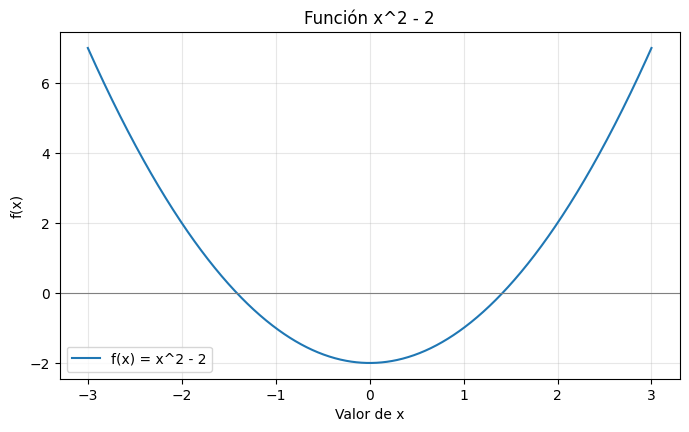

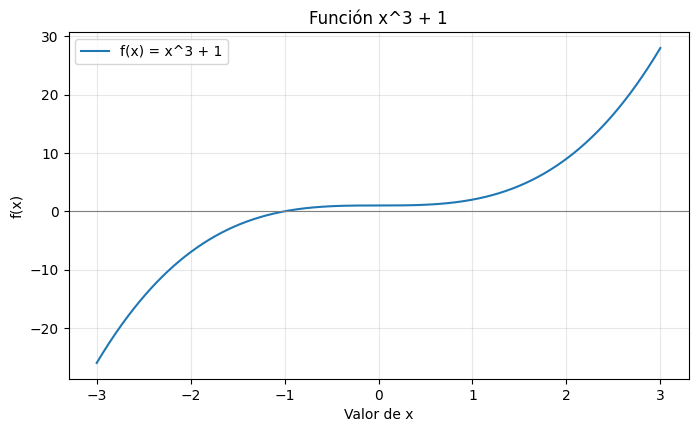

In [8]:
escala = 3
n = 1000
x = np.linspace(-escala, escala, n)

graficar_funcion(f_x_cuad_menos_2, x, 'Función x^2 - 2', 'f(x) = x^2 - 2')
graficar_funcion(f_x_cubo_mas_1, x, 'Función x^3 + 1', 'f(x) = x^3 + 1')

Ya que las dibujé, reviso si cumplen las propiedades de una densidad en el intervalo $[-3, 3]$: que no tengan valores negativos y que el área total sea 1.

In [9]:
revisar_densidad(f_x_cuad_menos_2, -3, 3, 'f(x) = x^2 - 2')
revisar_densidad(f_x_cubo_mas_1, -3, 3, 'f(x) = x^3 + 1')

f(x) = x^2 - 2
  Valor mínimo de f(x): -2.0000 -> hay valores negativos
  Área bajo la curva en [-3.0, 3.0]: 6.0000 -> no vale 1
  ¿Es una densidad válida? No

f(x) = x^3 + 1
  Valor mínimo de f(x): -26.0000 -> hay valores negativos
  Área bajo la curva en [-3.0, 3.0]: 6.0000 -> no vale 1
  ¿Es una densidad válida? No



Las dos fallan: tienen valores negativos y el área no es 1. O sea que, aunque se pueden graficar, **no son funciones de densidad de probabilidad** de verdad. Sirven para practicar cómo se visualiza una función, pero no se pueden usar para calcular probabilidades.

## Densidad de una distribución uniforme

$$f(x) = \frac{1}{b-a}$$

**Ejemplo:** una pizza puede llegar en cualquier momento entre los 20 y los 40 minutos, y todos los tiempos de ese intervalo son igual de probables. Si llega antes de 20 minutos o después de 40, la densidad es 0.

Entonces $a = 20$, $b = 40$ y la densidad vale $\frac{1}{40-20} = 0.05$ en todo el intervalo.

Primero calculo la densidad en $x = 30$ minutos con mi función y con `uniform.pdf` de scipy, para ver que dan lo mismo.

In [10]:
a = 20
b = 40
x_pizza = 30

# Con mi función
dens_mia = float(f_x_uniforme(x_pizza, a, b))
print("Densidad en x =", x_pizza, "con f_x_uniforme():", dens_mia)

# Con la librería scipy (loc = a, scale = b - a)
dens_scipy = uniform.pdf(x_pizza, loc=a, scale=b - a)
print("Densidad en x =", x_pizza, "con uniform.pdf():  ", dens_scipy)

Densidad en x = 30 con f_x_uniforme(): 0.05
Densidad en x = 30 con uniform.pdf():   0.05


Ahora visualizo la densidad. Uso valores de `x` entre 0 y 60 para que se vea cómo la densidad es 0 antes de los 20 y después de los 40 minutos.

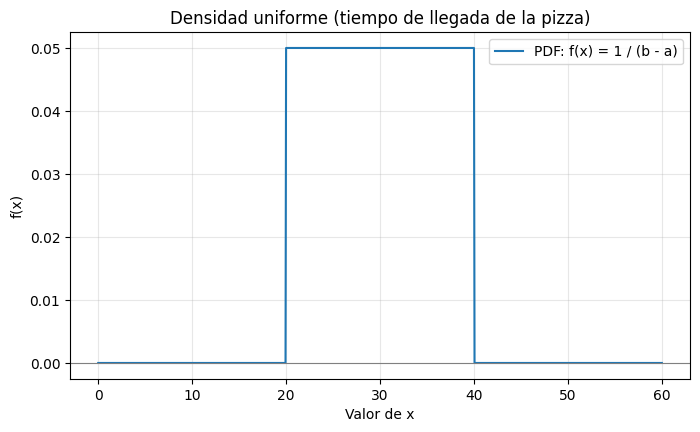

In [11]:
x = np.linspace(0, 60, 1000)
graficar_funcion(lambda t: f_x_uniforme(t, a, b), x,
                 'Densidad uniforme (tiempo de llegada de la pizza)',
                 'PDF: f(x) = 1 / (b - a)')

Ahora uso los 1000 tiempos de entrega que cargué del CSV. Con el histograma se ve que los datos se reparten parejo entre 20 y 40, y la línea es la densidad teórica.

Primeros 10 tiempos del CSV (minutos):
[36.98 23.58 21.09 27.23 25.51 30.6  26.12 26.09 22.23 25.  ]


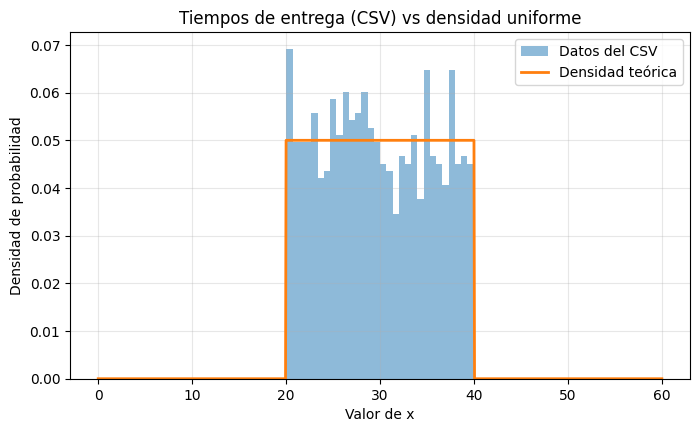

In [12]:
print("Primeros 10 tiempos del CSV (minutos):")
print(np.round(tiempos[:10], 2))

x = np.linspace(0, 60, 1000)
graficar_datos_y_densidad(tiempos, lambda t: f_x_uniforme(t, a, b), x,
                          'Tiempos de entrega (CSV) vs densidad uniforme',
                          'Densidad teórica')

### Probabilidades, valor esperado y varianza (uniforme)

Aquí calculo con la integral (y con el `cdf` de scipy para comprobar):

- $P(X \le 30)$
- $P(25 \le X \le 35)$
- $P(X > 35)$
- el valor esperado, la varianza y la desviación estándar

En la teoría de la uniforme: $\mu = \frac{a+b}{2}$ y $\sigma^2 = \frac{(b-a)^2}{12}$.

In [13]:
f_unif = lambda t: f_x_uniforme(t, a, b)

# Probabilidades con la integral
p1 = calcular_probabilidad(f_unif, a, 30)
p2 = calcular_probabilidad(f_unif, 25, 35)
p3 = calcular_probabilidad(f_unif, 35, b)

# Las mismas con la CDF de scipy (F(x) = P(X <= x))
cdf30 = uniform.cdf(30, loc=a, scale=b - a)
p2_cdf = uniform.cdf(35, loc=a, scale=b - a) - uniform.cdf(25, loc=a, scale=b - a)
p3_cdf = 1 - uniform.cdf(35, loc=a, scale=b - a)

print(f"P(X <= 30)       integral = {p1:.4f}   cdf = {cdf30:.4f}")
print(f"P(25 <= X <= 35) integral = {p2:.4f}   cdf = {p2_cdf:.4f}")
print(f"P(X > 35)        integral = {p3:.4f}   cdf = {p3_cdf:.4f}")

# Valor esperado, varianza y desviación estándar
mu_u, var_u, sd_u = calcular_media_varianza(f_unif, a, b)
print(f"\nCon integrales: media = {mu_u:.4f}, varianza = {var_u:.4f}, desv. estándar = {sd_u:.4f}")
print(f"Con la fórmula: media = {(a + b) / 2:.4f}, varianza = {(b - a) ** 2 / 12:.4f}, "
      f"desv. estándar = {math.sqrt((b - a) ** 2 / 12):.4f}")
print(f"Con scipy:      media = {uniform.mean(loc=a, scale=b - a):.4f}, "
      f"varianza = {uniform.var(loc=a, scale=b - a):.4f}")
print(f"\nDe los datos del CSV: media = {tiempos.mean():.4f}, varianza = {tiempos.var():.4f}")

P(X <= 30)       integral = 0.5000   cdf = 0.5000
P(25 <= X <= 35) integral = 0.5000   cdf = 0.5000
P(X > 35)        integral = 0.2500   cdf = 0.2500

Con integrales: media = 30.0000, varianza = 33.3333, desv. estándar = 5.7735
Con la fórmula: media = 30.0000, varianza = 33.3333, desv. estándar = 5.7735
Con scipy:      media = 30.0000, varianza = 33.3333

De los datos del CSV: media = 29.7172, varianza = 33.6848


Y para ver la probabilidad como un área, sombreo la zona entre 25 y 35 minutos (probabilidad de que la pizza llegue en ese rango).

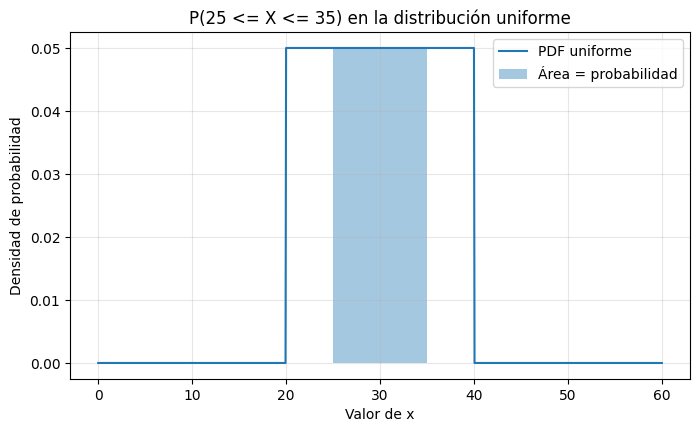

In [14]:
x = np.linspace(0, 60, 1000)
graficar_area(lambda t: f_x_uniforme(t, a, b), x, 25, 35,
              'P(25 <= X <= 35) en la distribución uniforme',
              'PDF uniforme')

## Normal

$$f(x) =\frac{1}{\sigma \cdot \sqrt{2 \cdot \pi}}\cdot e^{\frac{-1}{2}\cdot \left( \frac {x - \mu}{\sigma}\right) ^2}$$

**Ejemplo:** las calificaciones promedio de los alumnos con una media de $\mu = 85$ y una desviación estándar de $\sigma = 5$.

Primero calculo la densidad en $x = 80$ con mi función y con `norm.pdf` de scipy.

In [15]:
media = 85
desviacion_estandar = 5
x_cal = 80
print("media =", media)
print("desviación estándar =", desviacion_estandar)

# Con mi función
dens_mia = float(f_x_normal(x_cal, media, desviacion_estandar))
print("Densidad en x =", x_cal, "con f_x_normal():", dens_mia)

# Con la librería scipy
dens_scipy = norm.pdf(x_cal, media, desviacion_estandar)
print("Densidad en x =", x_cal, "con norm.pdf():  ", dens_scipy)

media = 85
desviación estándar = 5
Densidad en x = 80 con f_x_normal(): 0.04839414490382868
Densidad en x = 80 con norm.pdf():   0.04839414490382867


Ahora comparo con la campana las calificaciones de los 1000 alumnos que cargué del CSV. Para graficar uso el rango de $\mu \pm 4\sigma$, que es donde está casi toda la probabilidad.

Primeras 10 calificaciones del CSV:
[81.99 85.61 88.28 82.71 89.11 80.77 81.09 92.99 90.3  82.28]


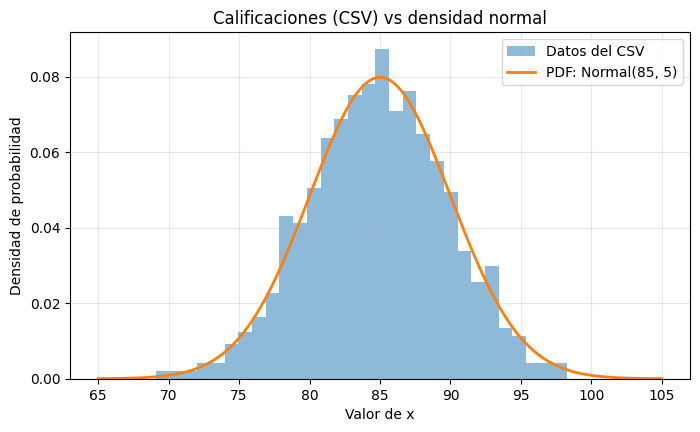

In [16]:
print("Primeras 10 calificaciones del CSV:")
print(np.round(calificaciones[:10], 2))

x = np.linspace(media - 4 * desviacion_estandar, media + 4 * desviacion_estandar, 1000)
graficar_datos_y_densidad(calificaciones, lambda t: f_x_normal(t, media, desviacion_estandar), x,
                          'Calificaciones (CSV) vs densidad normal',
                          f'PDF: Normal({media}, {desviacion_estandar})')

### Probabilidades, valor esperado y varianza (normal)

Calculo estas probabilidades:

- $P(X \ge 90)$: que un alumno saque 90 o más
- $P(80 \le X \le 90)$: que saque entre 80 y 90 (a un desvío de la media)
- $P(X < 70)$: que saque menos de 70
- $F(85)$: la probabilidad acumulada hasta la media

Como la normal va de $-\infty$ a $\infty$, para la integral uso `-np.inf` e `np.inf` en los límites que lo necesiten.

In [17]:
f_norm = lambda t: f_x_normal(t, media, desviacion_estandar)

p_mayor90 = calcular_probabilidad(f_norm, 90, np.inf)
p_80_90 = calcular_probabilidad(f_norm, 80, 90)
p_menor70 = calcular_probabilidad(f_norm, -np.inf, 70)
F_85 = calcular_probabilidad(f_norm, -np.inf, 85)

print(f"P(X >= 90)        integral = {p_mayor90:.4f}   scipy = {1 - norm.cdf(90, media, desviacion_estandar):.4f}")
print(f"P(80 <= X <= 90)  integral = {p_80_90:.4f}   scipy = {norm.cdf(90, media, desviacion_estandar) - norm.cdf(80, media, desviacion_estandar):.4f}")
print(f"P(X < 70)         integral = {p_menor70:.4f}   scipy = {norm.cdf(70, media, desviacion_estandar):.4f}")
print(f"F(85) = P(X <= 85) integral = {F_85:.4f}   scipy = {norm.cdf(85, media, desviacion_estandar):.4f}")

mu_n, var_n, sd_n = calcular_media_varianza(f_norm, -np.inf, np.inf)
print(f"\nCon integrales: media = {mu_n:.4f}, varianza = {var_n:.4f}, desv. estándar = {sd_n:.4f}")
print(f"Con scipy:      media = {norm.mean(media, desviacion_estandar):.4f}, varianza = {norm.var(media, desviacion_estandar):.4f}")
print(f"\nDe los datos del CSV: media = {calificaciones.mean():.4f}, desv. estándar = {calificaciones.std():.4f}")

P(X >= 90)        integral = 0.1587   scipy = 0.1587
P(80 <= X <= 90)  integral = 0.6827   scipy = 0.6827
P(X < 70)         integral = 0.0013   scipy = 0.0013
F(85) = P(X <= 85) integral = 0.5000   scipy = 0.5000

Con integrales: media = 85.0000, varianza = 25.0000, desv. estándar = 5.0000
Con scipy:      media = 85.0000, varianza = 25.0000

De los datos del CSV: media = 84.8440, desv. estándar = 4.8980


Sombreo dos zonas para verlo mejor: el área entre 80 y 90, y el área de 90 para arriba.

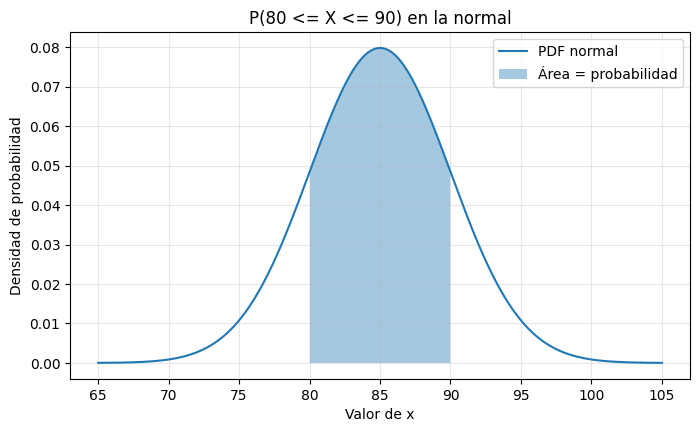

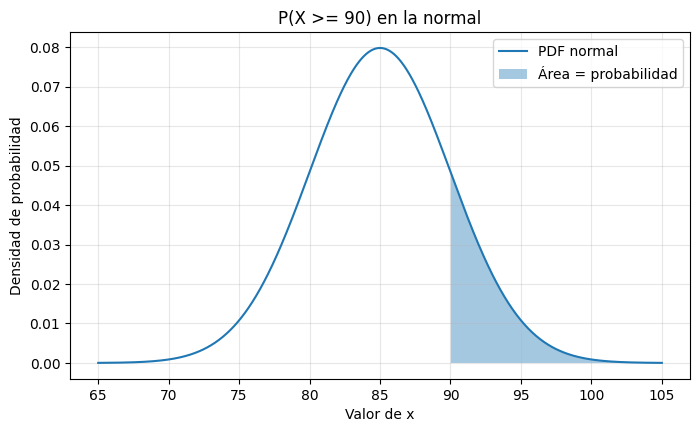

In [18]:
x = np.linspace(media - 4 * desviacion_estandar, media + 4 * desviacion_estandar, 1000)
graficar_area(f_norm, x, 80, 90, 'P(80 <= X <= 90) en la normal', 'PDF normal')
graficar_area(f_norm, x, 90, x.max(), 'P(X >= 90) en la normal', 'PDF normal')

## Función chi cuadrada

$$f(x) = \frac{x^{(k/2 - 1)} \cdot e^{(-x/2)}}{2^{(k/2)} \cdot \Gamma(k/2)} \qquad x \in (0, \infty)$$

Aquí $k$ son los grados de libertad (cuando se usa con una muestra, normalmente es $n-1$). Uso $k = 8$ y calculo la densidad en $x = 3$ con mi función y con `chi2.pdf`.

In [19]:
x_chi = 3
gl = 8  # grados de libertad (n - 1)

dens_mia = float(f_x_chi_cuadrada(x_chi, gl))
print("Densidad en x =", x_chi, "con", gl, "grados de libertad, f_x_chi_cuadrada():", dens_mia)

dens_scipy = chi2.pdf(x_chi, gl)
print("Densidad en x =", x_chi, "con", gl, "grados de libertad, chi2.pdf():         ", dens_scipy)

Densidad en x = 3 con 8 grados de libertad, f_x_chi_cuadrada(): 0.06275535754174588
Densidad en x = 3 con 8 grados de libertad, chi2.pdf():          0.0627553575417459


Comparo con la densidad los 1000 valores de la chi cuadrada que cargué del CSV. A diferencia de la normal, esta curva **no es simétrica**: tiene una cola larga hacia la derecha.

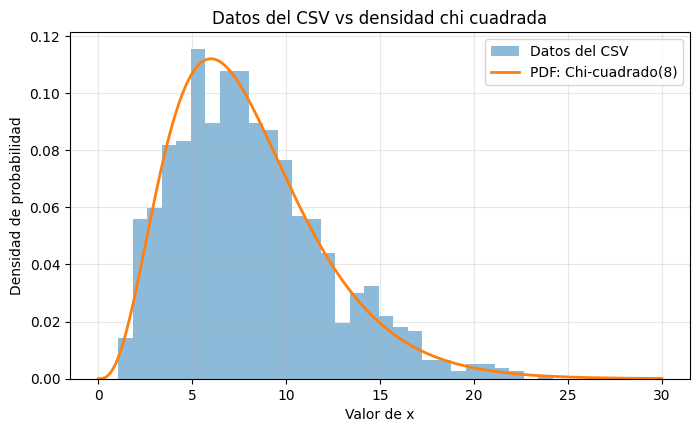

In [20]:
x = np.linspace(0, 30, 1000)
graficar_datos_y_densidad(datos_chi, lambda t: f_x_chi_cuadrada(t, gl), x,
                          'Datos del CSV vs densidad chi cuadrada',
                          f'PDF: Chi-cuadrado({gl})')

### Probabilidades, valor esperado y varianza (chi cuadrada)

Calculo $P(X \le 8)$ y $P(X > 15.51)$. El valor 15.51 sale de la tabla de chi cuadrada con 8 grados de libertad y 5 % de área en la cola derecha, así que la segunda probabilidad debería dar casi 0.05.

Para esta distribución la teoría dice que $\mu = k$ y $\sigma^2 = 2k$.

In [21]:
f_chi = lambda t: f_x_chi_cuadrada(t, gl)

p_menor8 = calcular_probabilidad(f_chi, 0, 8)
p_mayor15 = calcular_probabilidad(f_chi, 15.51, np.inf)

print(f"P(X <= 8)     integral = {p_menor8:.4f}   scipy = {chi2.cdf(8, gl):.4f}")
print(f"P(X > 15.51)  integral = {p_mayor15:.4f}   scipy = {chi2.sf(15.51, gl):.4f}")

mu_c, var_c, sd_c = calcular_media_varianza(f_chi, 0, np.inf)
print(f"\nCon integrales: media = {mu_c:.4f}, varianza = {var_c:.4f}, desv. estándar = {sd_c:.4f}")
print(f"Con la fórmula: media = {gl}, varianza = {2 * gl}, desv. estándar = {math.sqrt(2 * gl):.4f}")
print(f"\nDe los datos del CSV: media = {datos_chi.mean():.4f}, varianza = {datos_chi.var():.4f}")

P(X <= 8)     integral = 0.5665   scipy = 0.5665
P(X > 15.51)  integral = 0.0500   scipy = 0.0500

Con integrales: media = 8.0000, varianza = 16.0000, desv. estándar = 4.0000
Con la fórmula: media = 8, varianza = 16, desv. estándar = 4.0000

De los datos del CSV: media = 8.1225, varianza = 16.3619


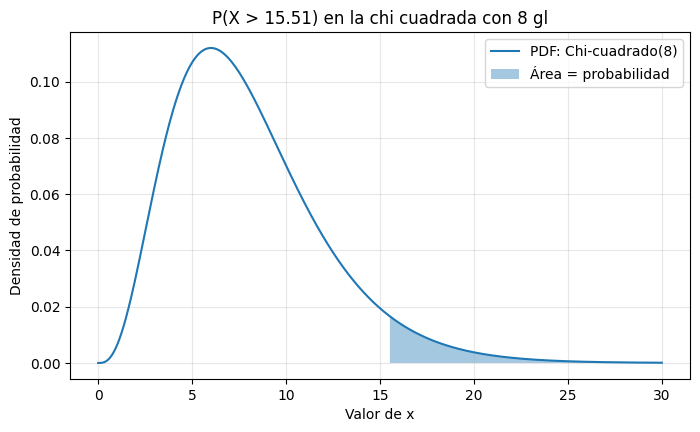

In [22]:
x = np.linspace(0, 30, 1000)
graficar_area(f_chi, x, 15.51, 30, 'P(X > 15.51) en la chi cuadrada con 8 gl', f'PDF: Chi-cuadrado({gl})')

## Función inventada

$$f(x)=(3x^6)^\frac{1}{3}$$

Esta es la función inventada que viene en el caso. Primero la visualizo en el intervalo de -3 a 3.

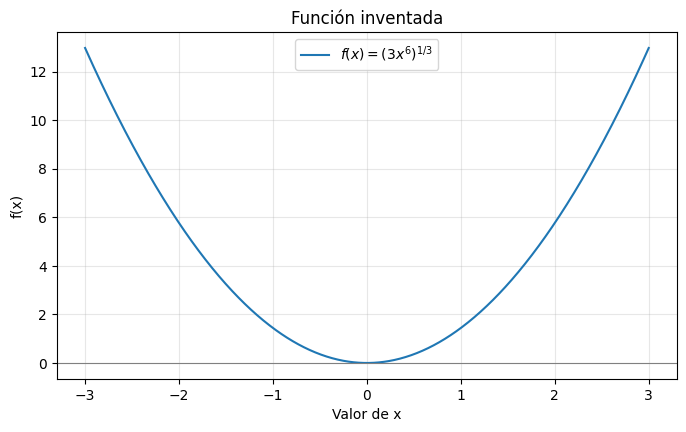

In [23]:
x = np.linspace(-3, 3, 1000)
graficar_funcion(f_x_inventada, x, 'Función inventada', r'$f(x)=(3x^6)^{1/3}$')

Igual que con las otras dos, reviso si es una densidad válida. Como $(3x^6)^{1/3} = 3^{1/3}\cdot x^2$, nunca da negativos, pero el área seguramente no es 1.

In [24]:
revisar_densidad(f_x_inventada, -3, 3, 'f(x) = (3x^6)^(1/3)')

f(x) = (3x^6)^(1/3)
  Valor mínimo de f(x): 0.0000 -> no es negativa
  Área bajo la curva en [-3.0, 3.0]: 25.9605 -> no vale 1
  ¿Es una densidad válida? No



Efectivamente, no es negativa pero el área es mucho mayor que 1, así que todavía no es una densidad. Eso se arregla fácil: si divido la función entre su área, el área total pasa a ser 1 y ya cumple las dos propiedades. A esa constante se le llama constante de normalización.

$$f_{nueva}(x) = \frac{f(x)}{\text{área}}$$

Con eso ya puedo calcular la media, la varianza y una probabilidad, por ejemplo $P(1 \le X \le 3)$.

Área original: 25.9605
f(x) inventada normalizada
  Valor mínimo de f(x): 0.0000 -> no es negativa
  Área bajo la curva en [-3.0, 3.0]: 1.0000 -> vale 1
  ¿Es una densidad válida? Sí

Media = 0.0000, varianza = 5.4000, desv. estándar = 2.3238
P(1 <= X <= 3) = 0.4815


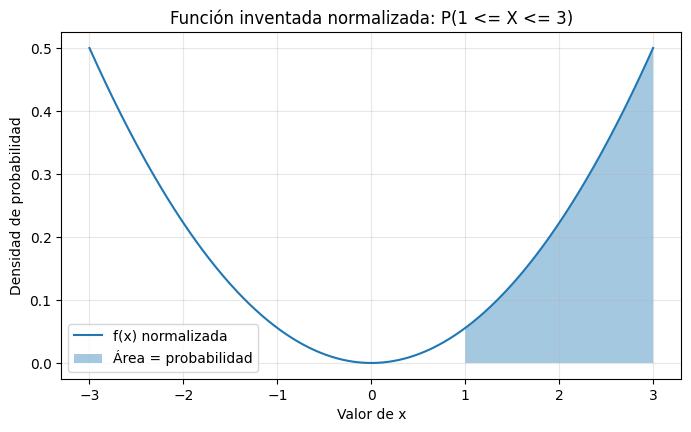

In [25]:
# Constante de normalización: 1 / área de la función en [-3, 3]
area_inventada = quad(lambda t: float(f_x_inventada(t)), -3, 3)[0]
print("Área original:", round(area_inventada, 4))

def f_x_inventada_norm(x):
    return f_x_inventada(x) / area_inventada

revisar_densidad(f_x_inventada_norm, -3, 3, 'f(x) inventada normalizada')

mu_i, var_i, sd_i = calcular_media_varianza(f_x_inventada_norm, -3, 3)
print(f"Media = {mu_i:.4f}, varianza = {var_i:.4f}, desv. estándar = {sd_i:.4f}")

p_1_3 = calcular_probabilidad(f_x_inventada_norm, 1, 3)
print(f"P(1 <= X <= 3) = {p_1_3:.4f}")

x = np.linspace(-3, 3, 1000)
graficar_area(f_x_inventada_norm, x, 1, 3, 'Función inventada normalizada: P(1 <= X <= 3)',
              'f(x) normalizada')

## Resumen de resultados

Junto en una sola tabla lo que se calculó con las integrales para cada distribución.

In [26]:
resumen = [
    ("Uniforme (20, 40)",        mu_u, var_u, sd_u),
    ("Normal (85, 5)",           mu_n, var_n, sd_n),
    ("Chi cuadrada (8 gl)",      mu_c, var_c, sd_c),
    ("Inventada normalizada",    mu_i, var_i, sd_i),
]

print(f"{'Distribución':<26}{'Media':>10}{'Varianza':>12}{'Desv. est.':>12}")
print("-" * 60)
for nombre, m, v, s in resumen:
    print(f"{nombre:<26}{m:>10.4f}{v:>12.4f}{s:>12.4f}")

Distribución                   Media    Varianza  Desv. est.
------------------------------------------------------------
Uniforme (20, 40)            30.0000     33.3333      5.7735
Normal (85, 5)               85.0000     25.0000      5.0000
Chi cuadrada (8 gl)           8.0000     16.0000      4.0000
Inventada normalizada         0.0000      5.4000      2.3238


# Interpretación

**¿Qué significa la densidad de una función $f(x)$ que identifica variables aleatorias continuas?**

Es la función que nos dice cómo se reparte la probabilidad. Donde la curva está más alta es más probable que salga un valor, y donde está baja es menos probable. Ojo, el valor de $f(x)$ no es la probabilidad. En una variable continua la probabilidad de un valor exacto es 0 (por ejemplo, que la pizza llegue justo a los 30.0000 minutos). La probabilidad es el área bajo la curva entre dos valores. Para que una función sea una densidad no puede dar valores negativos y el área total tiene que ser 1. Lo comprobé en el código: $x^2-2$ y $x^3+1$ no cumplen, y la inventada tampoco hasta que la dividí entre su área.

**¿Qué significa probabilidad acumulada de una función $f(x)$ que trata con variables aleatorias continuas?**

Es la probabilidad de que la variable sea menor o igual a un valor, o sea $F(x) = P(X \le x)$. Es el área de la curva desde la izquierda hasta ese punto. Siempre va de 0 a 1 y nunca baja. Por ejemplo, en la uniforme $F(30) = 0.5$ porque 30 minutos está a la mitad entre 20 y 40. En la normal $F(85) = 0.5$ porque 85 es la media. También sirve para sacar la probabilidad de un intervalo con $F(b) - F(a)$. En el código lo comparé con el `cdf` de scipy y me dio lo mismo.

**¿Qué significa valor esperado de una función $f(x)$ que trata con variables aleatorias continuas?**

Es el promedio de todos los valores posibles, pero los valores más probables pesan más. Es el centro de la distribución, el valor al que se acerca el promedio si repites el experimento muchas veces. En los ejemplos, la pizza tarda 30 minutos en promedio, las calificaciones 85 y la chi cuadrada con 8 grados de libertad tiene media 8. Con los datos de los CSV el promedio salió casi igual pero no exacto, porque son solo 1000 datos.

**¿Qué significa varianza y desviación estándar de una función $f(x)$ que trata con variables aleatorias continuas?**

Dicen qué tan separados están los valores de la media. La varianza sale en unidades al cuadrado, por eso se le saca raíz cuadrada y queda la desviación estándar, que ya está en las mismas unidades que los datos. Si la desviación es chica la curva queda alta y angosta, y si es grande queda baja y ancha. En la uniforme la varianza es 33.33 y la desviación 5.77 minutos. En la normal la desviación es 5, y por eso la probabilidad de sacar entre 80 y 90 salió 0.6827. En la chi cuadrada la varianza es 16 y la desviación 4.

**¿Cuál sería un ejemplo de una función de densidad con variables aleatorias continuas?**

El de la pizza. Puede llegar en cualquier momento entre los 20 y los 40 minutos y todos los tiempos son igual de probables, así que $f(x) = 0.05$. Es una densidad válida porque no es negativa y el área es $0.05 \times 20 = 1$. Con ella saqué que la probabilidad de que llegue entre los 25 y los 35 minutos es 0.5. Otros ejemplos del caso son las calificaciones con la normal y la chi cuadrada.

# Conclusión

En este caso vi que en las variables continuas todo es área bajo la curva. La probabilidad es un área, la acumulada es el área hasta un punto, y la media y la varianza salen de integrales. También vi que no cualquier función sirve como densidad, hay que checar que no sea negativa y que el área total sea 1. Si el área no da 1 se puede arreglar dividiendo entre el área. Y los datos de los CSV se parecieron bastante a su densidad teórica.